In [ ]:
import pandas as pd

In [ ]:
clean_file_path = os.path.join(
    project_folder,
    'clean_transactions.csv'
)

df_clean.to_csv(clean_file_path, index=False)

print("✅ Clean transaction file saved!")
print(clean_file_path)
print("Rows:", len(df_clean))

NameError: name 'os' is not defined

In [3]:
import pandas as pd

df_clean = pd.read_csv('/content/clean_transactions.csv')

print("Dataset loaded successfully!")
print("Shape:", df_clean.shape)

df_clean.head()

/tmp/ipykernel_2591/975724823.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_clean = pd.read_csv('/content/clean_transactions.csv')


Dataset loaded successfully!
Shape: (1007914, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [8]:
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'],
    errors='coerce'
)

customer_df = df_clean.dropna(
    subset=['Customer ID']
).copy()

print("Customer data restored!")
print("Customer records:", len(customer_df))
print("Unique customers:", customer_df['Customer ID'].nunique())

Customer data restored!
Customer records: 779425
Unique customers: 5878


In [10]:
customer_summary = (
    customer_df
    .groupby('Customer ID')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Quantity=('Quantity', 'sum'),
        Last_Purchase=('InvoiceDate', 'max'),
        First_Purchase=('InvoiceDate', 'min')
    )
    .reset_index()
)

In [11]:
customer_summary = (
    customer_df
    .groupby('Customer ID')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Quantity=('Quantity', 'sum'),
        Last_Purchase=('InvoiceDate', 'max'),
        First_Purchase=('InvoiceDate', 'min')
    )
    .reset_index()
)

In [12]:
customer_summary['Average_Order_Value'] = (
    customer_summary['Revenue'] / customer_summary['Orders']
)

top_10_customers = (
    customer_summary
    .sort_values('Revenue', ascending=False)
    .head(10)
)

print("Customer summary created!")
print("Total customers:", len(customer_summary))
print("\nTop 10 customers by revenue:")
display(top_10_customers)

Customer summary created!
Total customers: 5878

Top 10 customers by revenue:


,Customer ID,Revenue,Orders,Quantity,Last_Purchase,First_Purchase,Average_Order_Value
5692,18102.0,580987.04,145,181645,2011-12-09 11:50:00,2009-12-01 09:24:00,4006.807172
2277,14646.0,528602.52,151,367193,2011-12-08 12:12:00,2009-12-02 16:52:00,3500.678940
1789,14156.0,313437.62,156,164325,2011-11-30 10:54:00,2009-12-01 12:30:00,2009.215513
2538,14911.0,291420.81,398,147972,2011-12-08 15:54:00,2009-12-01 11:41:00,732.213090
5050,17450.0,244784.25,51,83914,2011-12-01 13:29:00,2010-09-27 16:59:00,4799.691176
1331,13694.0,195640.69,143,188201,2011-12-06 09:32:00,2009-12-04 15:26:00,1368.116713
5109,17511.0,172132.87,60,117174,2011-12-07 10:12:00,2009-12-02 10:52:00,2868.881167
4061,16446.0,168472.50,2,80997,2011-12-09 09:15:00,2011-05-18 09:52:00,84236.250000
4295,16684.0,147142.77,55,104810,2011-12-05 14:06:00,2009-12-07 12:56:00,2675.323091
68,12415.0,144458.37,28,91447,2011-11-15 14:22:00,2010-06-30 08:30:00,5159.227500


In [4]:
print("Column names:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

print("\nDataset shape:")
print(df_clean.shape)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']

Data types:
Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
Revenue        float64
dtype: object

Dataset shape:
(1007914, 9)


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'

os.makedirs(project_folder, exist_ok=True)

clean_file_path = os.path.join(
    project_folder,
    'clean_transactions.csv'
)

df_clean.to_csv(clean_file_path, index=False)

print("Clean dataset saved permanently!")
print("Location:", clean_file_path)
print("Rows saved:", len(df_clean))

Clean dataset saved permanently!
Location: /content/drive/MyDrive/Ecommerce_Analysis_Project/clean_transactions.csv
Rows saved: 1007914


In [7]:
import os

print(os.path.exists(clean_file_path))
print("File size (MB):", round(os.path.getsize(clean_file_path) / (1024**2), 2))

True
File size (MB): 91.31


In [1]:
import os
import pandas as pd

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'
file_path = os.path.join(project_folder, 'online_retail_II.xlsx')

print("✅ Setup complete")

✅ Setup complete


In [2]:
# Load both sheets
df_2009 = pd.read_excel(
    file_path,
    sheet_name='Year 2009-2010'
)

df_2010 = pd.read_excel(
    file_path,
    sheet_name='Year 2010-2011'
)

# Combine both years
df = pd.concat([df_2009, df_2010], ignore_index=True)

# Apply the same cleaning we used earlier
df_clean = df[
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].drop_duplicates().copy()

# Create Revenue column
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

print("✅ Clean dataset recreated!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Ecommerce_Analysis_Project/online_retail_II.xlsx'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'

print(os.listdir(project_folder))

['online_retail_II.xlsx', 'Visualizations', 'Results']


In [ ]:
id="m3k721"
import pandas as pd
import os

file_path = os.path.join(
    project_folder,
    'online_retail_II.xlsx'
)

# Load both sheets
df_2009 = pd.read_excel(file_path, sheet_name='Year 2009-2010')
df_2010 = pd.read_excel(file_path, sheet_name='Year 2010-2011')

# Combine both years
df = pd.concat([df_2009, df_2010], ignore_index=True)

# Same cleaning used in our analysis
df_clean = df[
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].drop_duplicates().copy()

# Revenue
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

print("✅ Clean dataset recreated!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

✅ Clean dataset recreated!
Rows: 1007914
Columns: 9


In [ ]:
clean_file_path = os.path.join(
    project_folder,
    'clean_transactions.csv'
)

df_clean.to_csv(clean_file_path, index=False)

print("✅ Clean transaction file saved!")
print("Rows:", len(df_clean))
print("File:", clean_file_path)

✅ Clean transaction file saved!
Rows: 1007914
File: /content/drive/MyDrive/Ecommerce_Analysis_Project/clean_transactions.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'

print("Files in project folder:")
print(os.listdir(project_folder))

Files in project folder:
['online_retail_II.xlsx', 'Visualizations', 'Results']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Project folders
project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'
visuals_folder = os.path.join(project_folder, 'Visualizations')
results_folder = os.path.join(project_folder, 'Results')

# Load the saved dataset
file_path = os.path.join(project_folder, 'online_retail_II.xlsx')

df_2009 = pd.read_excel(
    file_path,
    sheet_name='Year 2009-2010'
)

df_2010 = pd.read_excel(
    file_path,
    sheet_name='Year 2010-2011'
)

# Combine both years
df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("2009-2010:", df_2009.shape)
print("2010-2011:", df_2010.shape)
print("Combined:", df.shape)

Dataset loaded successfully!
2009-2010: (525461, 8)
2010-2011: (541910, 8)
Combined: (1067371, 8)


In [ ]:
# Clean the dataset
df_clean = df[
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].drop_duplicates().copy()

# Create revenue
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

# Create time-related columns
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month_Name'] = df_clean['InvoiceDate'].dt.strftime('%b')

# Customer-level dataset
customer_df = df_clean[
    df_clean['Customer ID'].notna()
].copy()

# Main metrics
total_revenue = df_clean['Revenue'].sum()
total_orders = df_clean['Invoice'].nunique()
total_customers = customer_df['Customer ID'].nunique()
aov = total_revenue / total_orders

print("Clean dataset recreated!")
print("Clean rows:", len(df_clean))
print(f"Revenue: £{total_revenue:,.2f}")
print(f"Orders: {total_orders:,}")
print(f"Customers: {total_customers:,}")
print(f"Average Order Value: £{aov:,.2f}")

Clean dataset recreated!
Clean rows: 1007914
Revenue: £20,476,634.02
Orders: 40,078
Customers: 5,878
Average Order Value: £510.92


In [ ]:
customer_summary = (
    customer_df
    .groupby('Customer ID')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Quantity=('Quantity', 'sum'),
        Last_Purchase=('InvoiceDate', 'max'),
        First_Purchase=('InvoiceDate', 'min')
    )
    .reset_index()
)

customer_summary['Average_Order_Value'] = (
    customer_summary['Revenue'] /
    customer_summary['Orders']
)

print("Customer-level dataset created!")
print("Customers:", len(customer_summary))
print("\nTop 10 Customers by Revenue:")
print(
    customer_summary
    .sort_values('Revenue', ascending=False)
    .head(10)
    .to_string(index=False)
)

Customer-level dataset created!
Customers: 5878

Top 10 Customers by Revenue:
 Customer ID   Revenue  Orders  Quantity       Last_Purchase      First_Purchase  Average_Order_Value
     18102.0 580987.04     145    181645 2011-12-09 11:50:00 2009-12-01 09:24:00          4006.807172
     14646.0 528602.52     151    367193 2011-12-08 12:12:00 2009-12-02 16:52:00          3500.678940
     14156.0 313437.62     156    164325 2011-11-30 10:54:00 2009-12-01 12:30:00          2009.215513
     14911.0 291420.81     398    147972 2011-12-08 15:54:00 2009-12-01 11:41:00           732.213090
     17450.0 244784.25      51     83914 2011-12-01 13:29:00 2010-09-27 16:59:00          4799.691176
     13694.0 195640.69     143    188201 2011-12-06 09:32:00 2009-12-04 15:26:00          1368.116713
     17511.0 172132.87      60    117174 2011-12-07 10:12:00 2009-12-02 10:52:00          2868.881167
     16446.0 168472.50       2     80997 2011-12-09 09:15:00 2011-05-18 09:52:00         84236.250000
    

In [ ]:
top_10_customers = (
    customer_summary
    .sort_values('Revenue', ascending=False)
    .head(10)
)

top_10_revenue = top_10_customers['Revenue'].sum()

top_10_revenue_share = (
    top_10_revenue /
    customer_summary['Revenue'].sum()
) * 100

print(f"Top 10 customers' revenue: £{top_10_revenue:,.2f}")
print(f"Top 10 customers' revenue share: {top_10_revenue_share:.2f}%")

Top 10 customers' revenue: £2,787,079.44
Top 10 customers' revenue share: 16.04%


In [ ]:
overall_avg_customer_revenue = (
    customer_summary['Revenue'].mean()
)

top_10_avg_customer_revenue = (
    top_10_customers['Revenue'].mean()
)

multiple = (
    top_10_avg_customer_revenue /
    overall_avg_customer_revenue
)

print(f"Overall average revenue per customer: £{overall_avg_customer_revenue:,.2f}")
print(f"Top 10 average revenue per customer: £{top_10_avg_customer_revenue:,.2f}")
print(f"Top 10 customers generate approximately {multiple:.2f}x the average customer revenue.")

Overall average revenue per customer: £2,955.90
Top 10 average revenue per customer: £278,707.94
Top 10 customers generate approximately 94.29x the average customer revenue.


In [ ]:
monthly_analysis = (
    df_clean
    .groupby('Month')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique')
    )
    .reset_index()
)

monthly_analysis['AOV'] = (
    monthly_analysis['Revenue'] /
    monthly_analysis['Orders']
)

monthly_analysis['Month'] = monthly_analysis['Month'].astype(str)

print("Monthly Sales Analysis:")
print(monthly_analysis.to_string(index=False))

Monthly Sales Analysis:
  Month     Revenue  Orders        AOV
2009-12  822483.950    1682 488.991647
2010-01  651155.112    1105 589.280644
2010-02  551878.296    1202 459.133358
2010-03  830915.261    1681 494.298192
2010-04  678875.252    1462 464.346958
2010-05  657705.500    1500 438.470333
2010-06  749537.310    1645 455.645781
2010-07  648810.270    1529 424.336344
2010-08  695251.910    1425 487.896077
2010-09  921696.991    1839 501.194666
2010-10 1161902.220    2301 504.955332
2010-11 1464293.142    2747 533.051744
2010-12  821452.730    1559 526.910026
2011-01  689811.610    1086 635.185645
2011-02  522545.560    1100 475.041418
2011-03  716215.260    1454 492.582710
2011-04  536968.491    1246 430.953845
2011-05  769296.610    1681 457.642243
2011-06  760547.010    1533 496.116771
2011-07  718076.121    1475 486.831268
2011-08  757841.380    1361 556.826877
2011-09 1056435.192    1837 575.087203
2011-10 1151263.730    2040 564.344966
2011-11 1503866.780    2769 543.108263
2

In [ ]:
# Convert Month back to datetime for analysis
monthly_comparison = monthly_analysis.copy()

monthly_comparison['Month_Date'] = pd.to_datetime(
    monthly_comparison['Month']
)

# Compare January-November 2010 vs January-November 2011
comparison = monthly_comparison[
    monthly_comparison['Month_Date'].dt.month <= 11
].copy()

comparison['Year'] = comparison['Month_Date'].dt.year

yearly_comparison = (
    comparison
    .groupby('Year')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Orders', 'sum')
    )
    .reset_index()
)

yearly_comparison['AOV'] = (
    yearly_comparison['Revenue'] /
    yearly_comparison['Orders']
)

print("January–November Comparison:")
print(yearly_comparison.to_string(index=False))

# Calculate growth from 2010 to 2011
revenue_growth = (
    (yearly_comparison.loc[
        yearly_comparison['Year'] == 2011, 'Revenue'
    ].iloc[0]
    /
    yearly_comparison.loc[
        yearly_comparison['Year'] == 2010, 'Revenue'
    ].iloc[0]) - 1
) * 100

orders_growth = (
    (yearly_comparison.loc[
        yearly_comparison['Year'] == 2011, 'Orders'
    ].iloc[0]
    /
    yearly_comparison.loc[
        yearly_comparison['Year'] == 2010, 'Orders'
    ].iloc[0]) - 1
) * 100

print(f"\nRevenue growth: {revenue_growth:.2f}%")
print(f"Order growth: {orders_growth:.2f}%")

January–November Comparison:
 Year     Revenue  Orders        AOV
 2010 9012021.264   18436 488.827363
 2011 9182867.744   17582 522.288007

Revenue growth: 1.90%
Order growth: -4.63%


In [ ]:
# Prepare comparable Jan-Nov data
country_year = df_clean.copy()

country_year['Year'] = country_year['InvoiceDate'].dt.year
country_year['Month_Number'] = country_year['InvoiceDate'].dt.month

country_year = country_year[
    (country_year['Month_Number'] <= 11) &
    (country_year['Year'].isin([2010, 2011]))
]

# Orders by country and year
country_orders = (
    country_year
    .groupby(['Country', 'Year'])
    .agg(
        Orders=('Invoice', 'nunique'),
        Revenue=('Revenue', 'sum')
    )
    .reset_index()
)

# Pivot for easier comparison
country_orders_pivot = country_orders.pivot(
    index='Country',
    columns='Year',
    values='Orders'
).fillna(0)

country_orders_pivot['Order_Change_%'] = (
    (country_orders_pivot.get(2011, 0) /
     country_orders_pivot.get(2010, 0).replace(0, np.nan)) - 1
) * 100

# Focus on countries with at least 50 orders in 2010
country_orders_pivot = country_orders_pivot[
    country_orders_pivot[2010] >= 50
].sort_values(
    'Order_Change_%'
)

print("Country Order Change — Jan-Nov 2010 vs Jan-Nov 2011:")
print(country_orders_pivot.to_string())

Country Order Change — Jan-Nov 2010 vs Jan-Nov 2011:
Year               2010     2011  Order_Change_%
Country                                         
Sweden             68.0     33.0      -51.470588
Netherlands       128.0     88.0      -31.250000
EIRE              318.0    261.0      -17.924528
United Kingdom  16922.0  15826.0       -6.476776
Germany           314.0    410.0       30.573248
Spain              59.0     84.0       42.372881
France            217.0    353.0       62.672811


In [ ]:
# Revenue comparison by country
country_revenue = (
    country_year
    .groupby(['Country', 'Year'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique')
    )
    .reset_index()
)

country_revenue_pivot = country_revenue.pivot(
    index='Country',
    columns='Year',
    values='Revenue'
).fillna(0)

# Keep countries with meaningful 2010 revenue
country_revenue_pivot = country_revenue_pivot[
    country_revenue_pivot[2010] >= 10000
].copy()

country_revenue_pivot['Revenue_Change_%'] = (
    (country_revenue_pivot[2011] /
     country_revenue_pivot[2010]) - 1
) * 100

country_revenue_pivot = country_revenue_pivot.sort_values(
    'Revenue_Change_%',
    ascending=False
)

print("Country Revenue Change — Jan-Nov 2010 vs Jan-Nov 2011:")
print(country_revenue_pivot.to_string())

Country Revenue Change — Jan-Nov 2010 vs Jan-Nov 2011:
Year                    2010         2011  Revenue_Change_%
Country                                                    
Australia          30558.550   137488.460        349.918141
Belgium            23743.880    37968.700         59.909417
Spain              38823.750    59398.620         52.995576
Norway             19671.750    29592.620         50.432066
Portugal           19778.900    28434.890         43.763758
France            134291.030   192732.140         43.518253
Switzerland        43028.590    55762.680         29.594486
Italy              14202.580    16471.290         15.973929
Germany           186511.041   205488.490         10.174974
Netherlands       253387.020   264933.840          4.556990
United Kingdom   7661428.303  7664042.134          0.034117
Channel Islands    23193.610    19878.610        -14.292730
Austria            11415.990     9238.280        -19.075963
EIRE              355527.050   265766.370    

In [ ]:
country_aov_analysis = (
    df_clean
    .groupby('Country')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Customers=('Customer ID', 'nunique')
    )
    .reset_index()
)

country_aov_analysis['AOV'] = (
    country_aov_analysis['Revenue'] /
    country_aov_analysis['Orders']
)

# Focus on countries with at least £50,000 revenue
meaningful_markets = country_aov_analysis[
    country_aov_analysis['Revenue'] >= 50000
].sort_values(
    'AOV',
    ascending=False
)

print("Countries with £50K+ Revenue — Ranked by AOV:")
print(
    meaningful_markets[
        ['Country', 'Revenue', 'Orders', 'Customers', 'AOV']
    ].to_string(index=False)
)

Countries with £50K+ Revenue — Ranked by AOV:
       Country      Revenue  Orders  Customers         AOV
   Netherlands   554038.090     228         22 2429.991623
     Australia   169283.460      95         15 1781.931158
       Denmark    68580.690      43         12 1594.899767
        Norway    56322.500      45         13 1251.611111
   Switzerland   100685.590      93         22 1082.640753
          EIRE   658767.310     626          5 1052.343946
        Sweden    91869.820     105         19  874.950667
         Spain   108332.490     154         41  703.457727
      Portugal    56283.530      95         24  592.458211
        France   350456.090     622         95  563.434228
       Germany   425019.711     789        107  538.681510
United Kingdom 17410569.687   36536       5350  476.531905
       Belgium    65387.820     149         29  438.844430


In [ ]:
product_performance = (
merchandise_products
    .groupby(['StockCode', 'Description'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Quantity_Sold=('Quantity_Sold', 'sum'),
        Orders=('Orders', 'sum')
    )
    .reset_index()
)

product_performance['Revenue_per_Unit'] = (
    product_performance['Revenue'] /
    product_performance['Quantity_Sold']
)

product_performance['Revenue_per_Order'] = (
    product_performance['Revenue'] /
    product_performance['Orders']
)

# Keep products with at least 100 orders
high_order_products = product_performance[
    product_performance['Orders'] >= 100
].copy()

high_order_products = high_order_products.sort_values(
    'Revenue',
    ascending=False
)

print("Top 20 Products with at least 100 Orders:")
print(
    high_order_products[
        [
            'Description',
            'Revenue',
            'Quantity_Sold',
            'Orders',
            'Revenue_per_Unit',
            'Revenue_per_Order'
        ]
    ].head(20).to_string(index=False)
)

NameError: name 'merchandise_products' is not defined

In [ ]:
product_performance = (
    merchandise_products
    .groupby(['StockCode', 'Description'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Quantity_Sold=('Quantity_Sold', 'sum'),
        Orders=('Orders', 'sum')
    )
    .reset_index()
)

product_performance['Revenue_per_Unit'] = (
    product_performance['Revenue'] /
    product_performance['Quantity_Sold']
)

product_performance['Revenue_per_Order'] = (
    product_performance['Revenue'] /
    product_performance['Orders']
)

# Keep products with at least 100 orders
high_order_products = product_performance[
    product_performance['Orders'] >= 100
].copy()

high_order_products = high_order_products.sort_values(
    'Revenue',
    ascending=False
)

print("Top 20 Products with at least 100 Orders:")
print(
    high_order_products[
        [
            'Description',
            'Revenue',
            'Quantity_Sold',
            'Orders',
            'Revenue_per_Unit',
            'Revenue_per_Order'
        ]
    ].head(20).to_string(index=False)
)

NameError: name 'merchandise_products' is not defined

In [ ]:
product_sales = (
    df_clean
    .groupby(['StockCode', 'Description'])
    .agg(
        Quantity_Sold=('Quantity', 'sum'),
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique')
    )
    .reset_index()
)

product_analysis = product_sales[
    (product_sales['Quantity_Sold'] > 0) &
    (product_sales['Revenue'] > 0) &
    (~product_sales['Description'].str.contains(
        'adjust|amazon|fee|bad debt',
        case=False,
        na=False
    ))
].copy()

excluded_products = ['Manual', 'DOTCOM POSTAGE', 'POSTAGE']

merchandise_products = product_analysis[
    ~product_analysis['Description'].isin(excluded_products)
].copy()

print("Merchandise products:", len(merchandise_products))

Merchandise products: 5581


In [ ]:
product_performance = (
    merchandise_products
    .groupby(['StockCode', 'Description'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Quantity_Sold=('Quantity_Sold', 'sum'),
        Orders=('Orders', 'sum')
    )
    .reset_index()
)

product_performance['Revenue_per_Unit'] = (
    product_performance['Revenue'] /
    product_performance['Quantity_Sold']
)

product_performance['Revenue_per_Order'] = (
    product_performance['Revenue'] /
    product_performance['Orders']
)

# Keep products with at least 100 orders
high_order_products = product_performance[
    product_performance['Orders'] >= 100
].copy()

high_order_products = high_order_products.sort_values(
    'Revenue',
    ascending=False
)

print("Top 20 Products with at least 100 Orders:")
print(
    high_order_products[
        [
            'Description',
            'Revenue',
            'Quantity_Sold',
            'Orders',
            'Revenue_per_Unit',
            'Revenue_per_Order'
        ]
    ].head(20).to_string(index=False)
)

Top 20 Products with at least 100 Orders:
                        Description   Revenue  Quantity_Sold  Orders  Revenue_per_Unit  Revenue_per_Order
           REGENCY CAKESTAND 3 TIER 330590.32          26478    3918         12.485472          84.377315
 WHITE HANGING HEART T-LIGHT HOLDER 257546.20          94142    5356          2.735721          48.085549
                      PARTY BUNTING 148318.28          28200    2674          5.259513          55.466821
            JUMBO BAG RED RETROSPOT 145961.83          77280    3245          1.888740          44.980533
      ASSORTED COLOUR BIRD ORNAMENT 129324.49          80082    2807          1.614901          46.072138
    PAPER CHAIN KIT 50'S CHRISTMAS  117760.29          35084    2018          3.356524          58.354950
     MEDIUM CERAMIC TOP STORAGE JAR  81700.92          78033     247          1.047005         330.772955
                      CHILLI LIGHTS  80540.88          15841    1135          5.084331          70.961128
ROTA

In [ ]:
# Products with at least 10,000 units sold
high_volume_products = product_performance[
    product_performance['Quantity_Sold'] >= 10000
].copy()

high_volume_products = high_volume_products.sort_values(
    'Revenue_per_Unit',
    ascending=True
)

print("High-Volume Products with Lowest Revenue per Unit:")
print(
    high_volume_products[
        [
            'Description',
            'Quantity_Sold',
            'Revenue',
            'Orders',
            'Revenue_per_Unit',
            'Revenue_per_Order'
        ]
    ].head(15).to_string(index=False)
)

High-Volume Products with Lowest Revenue per Unit:
                        Description  Quantity_Sold  Revenue  Orders  Revenue_per_Unit  Revenue_per_Order
ESSENTIAL BALM 3.5g TIN IN ENVELOPE          11396  1043.22      72          0.091543          14.489167
 BLACK SILVER FLOWER T-LIGHT HOLDER          11520  1138.04      23          0.098788          49.480000
            POP ART PEN CASE & PENS          10612  1054.70      31          0.099387          34.022581
              MINI HIGHLIGHTER PENS          15121  1544.52      50          0.102144          30.890400
       SET/6 FRUIT SALAD PAPER CUPS          16615  1816.73     136          0.109343          13.358309
        SET/6 STRAWBERRY PAPER CUPS          13290  1516.64      33          0.114119          45.958788
    DISCO BALL CHRISTMAS DECORATION          20951  2454.88     367          0.117172           6.689046
               JAZZ HEARTS MEMO PAD          10967  1334.11      32          0.121648          41.690938
    

In [ ]:
# Calculate median benchmarks
median_revenue = product_performance['Revenue'].median()
median_orders = product_performance['Orders'].median()

strong_products = product_performance[
    (product_performance['Revenue'] >= median_revenue) &
    (product_performance['Orders'] >= median_orders)
].copy()

strong_products = strong_products.sort_values(
    'Revenue',
    ascending=False
)

print("Median Revenue:", round(median_revenue, 2))
print("Median Orders:", round(median_orders, 0))

print("\nTop 20 Products with Strong Revenue and Demand:")
print(
    strong_products[
        [
            'Description',
            'Revenue',
            'Quantity_Sold',
            'Orders',
            'Revenue_per_Unit',
            'Revenue_per_Order'
        ]
    ].head(20).to_string(index=False)
)

Median Revenue: 911.76
Median Orders: 70.0

Top 20 Products with Strong Revenue and Demand:
                        Description   Revenue  Quantity_Sold  Orders  Revenue_per_Unit  Revenue_per_Order
           REGENCY CAKESTAND 3 TIER 330590.32          26478    3918         12.485472          84.377315
 WHITE HANGING HEART T-LIGHT HOLDER 257546.20          94142    5356          2.735721          48.085549
                      PARTY BUNTING 148318.28          28200    2674          5.259513          55.466821
            JUMBO BAG RED RETROSPOT 145961.83          77280    3245          1.888740          44.980533
      ASSORTED COLOUR BIRD ORNAMENT 129324.49          80082    2807          1.614901          46.072138
    PAPER CHAIN KIT 50'S CHRISTMAS  117760.29          35084    2018          3.356524          58.354950
     MEDIUM CERAMIC TOP STORAGE JAR  81700.92          78033     247          1.047005         330.772955
                      CHILLI LIGHTS  80540.88          15841

In [ ]:
# Products with above-median orders but below-median revenue
low_value_high_demand = product_performance[
    (product_performance['Orders'] > median_orders) &
    (product_performance['Revenue'] < median_revenue)
].copy()

low_value_high_demand = low_value_high_demand.sort_values(
    'Orders',
    ascending=False
)

print("High-Demand but Low-Revenue Products:")
print(
    low_value_high_demand[
        [
            'Description',
            'Revenue',
            'Quantity_Sold',
            'Orders',
            'Revenue_per_Unit',
            'Revenue_per_Order'
        ]
    ].head(20).to_string(index=False)
)

High-Demand but Low-Revenue Products:
                        Description  Revenue  Quantity_Sold  Orders  Revenue_per_Unit  Revenue_per_Order
               KITTY PENCIL ERASERS   593.29           2652     260          0.223714           2.281885
          PARTY TIME PENCIL ERASERS   559.54           2447     236          0.228664           2.370932
   HANGING WOOD AND FELT BUTTERFLY    665.91           1463     224          0.455167           2.972812
          TRAVEL CARD WALLET PANTRY   903.16           2002     221          0.451129           4.086697
BEADED CRYSTAL HEART GREEN ON STICK   730.74            948     216          0.770823           3.383056
        HANGING WOOD AND FELT HEART   570.09           1208     208          0.471929           2.740817
               PAINTED PINK RABBIT    807.60            937     194          0.861900           4.162887
              MINI JIGSAW DINOSAUR    846.82           1980     189          0.427687           4.480529
         QUEEN OF

In [ ]:
monthly_analysis_sorted = monthly_analysis.copy()

# Display months ranked by revenue
top_months = monthly_analysis_sorted.sort_values(
    'Revenue',
    ascending=False
).head(10)

print("Top 10 Months by Revenue:")
print(
    top_months[
        ['Month', 'Revenue', 'Orders', 'AOV']
    ].to_string(index=False)
)

Top 10 Months by Revenue:
  Month     Revenue  Orders        AOV
2011-11 1503866.780    2769 543.108263
2010-11 1464293.142    2747 533.051744
2010-10 1161902.220    2301 504.955332
2011-10 1151263.730    2040 564.344966
2011-09 1056435.192    1837 575.087203
2010-09  921696.991    1839 501.194666
2010-03  830915.261    1681 494.298192
2009-12  822483.950    1682 488.991647
2010-12  821452.730    1559 526.910026
2011-05  769296.610    1681 457.642243


In [ ]:
monthly_seasonality = monthly_analysis.copy()

monthly_seasonality['Month_Number'] = pd.to_datetime(
    monthly_seasonality['Month']
).dt.month

peak_months = monthly_seasonality[
    monthly_seasonality['Month_Number'].isin([9, 10, 11])
]

peak_revenue = peak_months['Revenue'].sum()
total_monthly_revenue = monthly_seasonality['Revenue'].sum()

peak_revenue_share = (
    peak_revenue / total_monthly_revenue
) * 100

print("September-November Revenue:", round(peak_revenue, 2))
print("Total Revenue:", round(total_monthly_revenue, 2))
print("September-November Revenue Share:", round(peak_revenue_share, 2), "%")

September-November Revenue: 7259458.06
Total Revenue: 20476634.02
September-November Revenue Share: 35.45 %


In [ ]:
peak_orders = peak_months['Orders'].sum()
total_orders_monthly = monthly_seasonality['Orders'].sum()

peak_order_share = (
    peak_orders / total_orders_monthly
) * 100

print("September-November Orders:", peak_orders)
print("Total Orders:", total_orders_monthly)
print("September-November Order Share:", round(peak_order_share, 2), "%")

September-November Orders: 13533
Total Orders: 40078
September-November Order Share: 33.77 %


In [ ]:
frequency_revenue = (
    customer_summary
    .groupby('Orders')
    .agg(
        Customers=('Customer ID', 'count'),
        Revenue=('Revenue', 'sum')
    )
    .reset_index()
)

frequency_revenue['Revenue_Share_%'] = (
    frequency_revenue['Revenue'] /
    frequency_revenue['Revenue'].sum()
) * 100

frequency_revenue = frequency_revenue.sort_values(
    'Orders'
)

print("Revenue by Customer Purchase Frequency:")
print(
    frequency_revenue.to_string(index=False)
)

Revenue by Customer Purchase Frequency:
 Orders  Customers    Revenue  Revenue_Share_%
      1       1623 560272.562         3.224627
      2        944 811434.853         4.670181
      3        664 788561.780         4.538536
      4        486 627776.741         3.613144
      5        360 677589.530         3.899840
      6        280 577768.851         3.325326
      7        222 573489.822         3.300698
      8        172 521891.740         3.003727
      9        153 555015.660         3.194371
     10         98 375056.440         2.158623
     11        131 522244.742         3.005759
     12         96 558680.671         3.215465
     13         79 393307.280         2.263665
     14         49 247505.201         1.424506
     15         51 293549.660         1.689513
     16         43 361484.360         2.080509
     17         41 350293.130         2.016098
     18         32 222336.881         1.279651
     19         26 235889.601         1.357653
     20         31 2

In [ ]:
# Save important analysis tables to the Results folder

customer_summary.to_csv(
    os.path.join(results_folder, 'customer_summary.csv'),
    index=False
)

rfm.to_csv(
    os.path.join(results_folder, 'rfm_customer_segments.csv'),
    index=False
)

country_analysis.to_csv(
    os.path.join(results_folder, 'country_analysis.csv'),
    index=False
)

product_performance.to_csv(
    os.path.join(results_folder, 'product_performance.csv'),
    index=False
)

monthly_analysis.to_csv(
    os.path.join(results_folder, 'monthly_analysis.csv'),
    index=False
)

frequency_revenue.to_csv(
    os.path.join(results_folder, 'frequency_revenue.csv'),
    index=False
)

print("All analysis tables saved successfully!")
print("\nFiles saved in Results folder:")
print(os.listdir(results_folder))

NameError: name 'rfm' is not defined

In [ ]:
# Save the analysis tables currently available in this Colab session

customer_summary.to_csv(
    os.path.join(results_folder, 'customer_summary.csv'),
    index=False
)

country_analysis.to_csv(
    os.path.join(results_folder, 'country_analysis.csv'),
    index=False
)

product_performance.to_csv(
    os.path.join(results_folder, 'product_performance.csv'),
    index=False
)

monthly_analysis.to_csv(
    os.path.join(results_folder, 'monthly_analysis.csv'),
    index=False
)

frequency_revenue.to_csv(
    os.path.join(results_folder, 'frequency_revenue.csv'),
    index=False
)

print("Current analysis tables saved successfully!")
print(os.listdir(results_folder))

NameError: name 'country_analysis' is not defined

In [ ]:
# ============================================================
# RECREATE & SAVE FINAL ANALYSIS TABLES
# ============================================================

# 1. Customer Summary
customer_df = df_clean[df_clean['Customer ID'].notna()].copy()

customer_summary = (
    customer_df
    .groupby('Customer ID')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Quantity=('Quantity', 'sum'),
        Last_Purchase=('InvoiceDate', 'max'),
        First_Purchase=('InvoiceDate', 'min')
    )
    .reset_index()
)

customer_summary['Average_Order_Value'] = (
    customer_summary['Revenue'] /
    customer_summary['Orders']
)


# 2. RFM Customer Segments
reference_date = df_clean['InvoiceDate'].max()

rfm = (
    customer_df
    .groupby('Customer ID')
    .agg(
        Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
        Frequency=('Invoice', 'nunique'),
        Monetary=('Revenue', 'sum')
    )
    .reset_index()
)

rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    5,
    labels=[5,4,3,2,1],
    duplicates='drop'
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1,2,3,4,5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1,2,3,4,5]
).astype(int)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

def segment_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 4:
        return 'Loyal Customers'
    elif r >= 4 and m >= 4:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 4 and m >= 4:
        return 'At Risk - High Value'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r >= 4 and f <= 2:
        return 'New / Promising'
    elif r <= 2 and f <= 2:
        return 'Low Engagement'
    else:
        return 'Need Attention'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)


# 3. Country Analysis
country_analysis = (
    df_clean
    .groupby('Country')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Customers=('Customer ID', 'nunique')
    )
    .reset_index()
)

country_analysis['AOV'] = (
    country_analysis['Revenue'] /
    country_analysis['Orders']
)

country_analysis['Revenue_Share'] = (
    country_analysis['Revenue'] /
    df_clean['Revenue'].sum()
) * 100

country_analysis = country_analysis.sort_values(
    'Revenue',
    ascending=False
)


# 4. Product Performance
product_performance = (
    merchandise_products
    .groupby(['StockCode', 'Description'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Quantity_Sold=('Quantity_Sold', 'sum'),
        Orders=('Orders', 'sum')
    )
    .reset_index()
)

product_performance['Revenue_per_Unit'] = (
    product_performance['Revenue'] /
    product_performance['Quantity_Sold']
)

product_performance['Revenue_per_Order'] = (
    product_performance['Revenue'] /
    product_performance['Orders']
)


# 5. Monthly Analysis
monthly_analysis = (
    df_clean
    .groupby('Month')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique')
    )
    .reset_index()
)

monthly_analysis['AOV'] = (
    monthly_analysis['Revenue'] /
    monthly_analysis['Orders']
)

monthly_analysis['Month'] = monthly_analysis['Month'].astype(str)


# 6. Purchase Frequency Revenue
frequency_revenue = (
    customer_summary
    .groupby('Orders')
    .agg(
        Customers=('Customer ID', 'count'),
        Revenue=('Revenue', 'sum')
    )
    .reset_index()
)

frequency_revenue['Revenue_Share_%'] = (
    frequency_revenue['Revenue'] /
    frequency_revenue['Revenue'].sum()
) * 100


# ============================================================
# SAVE EVERYTHING
# ============================================================

tables = {
    'customer_summary.csv': customer_summary,
    'rfm_customer_segments.csv': rfm,
    'country_analysis.csv': country_analysis,
    'product_performance.csv': product_performance,
    'monthly_analysis.csv': monthly_analysis,
    'frequency_revenue.csv': frequency_revenue
}

for filename, table in tables.items():
    table.to_csv(
        os.path.join(results_folder, filename),
        index=False
    )

print("✅ All 6 analysis tables saved successfully!\n")

for filename in tables:
    print("✓", filename)

print("\nResults folder:")
print(results_folder)

✅ All 6 analysis tables saved successfully!

✓ customer_summary.csv
✓ rfm_customer_segments.csv
✓ country_analysis.csv
✓ product_performance.csv
✓ monthly_analysis.csv
✓ frequency_revenue.csv

Results folder:
/content/drive/MyDrive/Ecommerce_Analysis_Project/Results


In [ ]:
duplicates = df_sales[df_sales.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))

NameError: name 'df_sales' is not defined

In [ ]:
# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# STEP 2: Load the Online Retail II dataset

file_path = '/content/online_retail_II.xlsx'

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name='Year 2009-2010'
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name='Year 2010-2011'
)

df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/online_retail_II.xlsx'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving online+retail+ii.zip to online+retail+ii (1).zip


In [ ]:
import zipfile
import os

zip_path = '/content/online+retail+ii (1).zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("File extracted successfully!")
print(os.listdir('/content'))

File extracted successfully!
['.config', 'online+retail+ii.zip', 'online_retail_II.xlsx', 'online+retail+ii (1).zip', 'sample_data']


In [ ]:
file_path = '/content/online_retail_II.xlsx'

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name='Year 2009-2010'
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name='Year 2010-2011'
)

df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset loaded successfully!
Rows: 1067371
Columns: 8


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'

os.makedirs(project_folder, exist_ok=True)

print("Project folder created!")
print(project_folder)

Project folder created!
/content/drive/MyDrive/Ecommerce_Analysis_Project


In [ ]:
import shutil

source = '/content/online_retail_II.xlsx'
destination = '/content/drive/MyDrive/Ecommerce_Analysis_Project/online_retail_II.xlsx'

shutil.copy2(source, destination)

print("Dataset permanently saved to Google Drive!")

Dataset permanently saved to Google Drive!


In [ ]:
import os

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'

visuals_folder = os.path.join(project_folder, 'Visualizations')
results_folder = os.path.join(project_folder, 'Results')

os.makedirs(visuals_folder, exist_ok=True)
os.makedirs(results_folder, exist_ok=True)

print("Folders created successfully!")
print("Visualizations:", visuals_folder)
print("Results:", results_folder)

Folders created successfully!
Visualizations: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations
Results: /content/drive/MyDrive/Ecommerce_Analysis_Project/Results


In [ ]:
# ============================================
# E-COMMERCE ANALYSIS — MASTER SETUP
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --------------------------------------------
# 1. Project folders
# --------------------------------------------

project_folder = '/content/drive/MyDrive/Ecommerce_Analysis_Project'
visuals_folder = os.path.join(project_folder, 'Visualizations')
results_folder = os.path.join(project_folder, 'Results')

os.makedirs(visuals_folder, exist_ok=True)
os.makedirs(results_folder, exist_ok=True)

# --------------------------------------------
# 2. Load dataset from Google Drive
# --------------------------------------------

file_path = os.path.join(
    project_folder,
    'online_retail_II.xlsx'
)

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name='Year 2009-2010'
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name='Year 2010-2011'
)

# Combine both years
df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

# --------------------------------------------
# 3. Basic cleaning
# --------------------------------------------

# Remove rows with invalid sales values
df_clean = df[
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# --------------------------------------------
# 4. Create Revenue
# --------------------------------------------

df_clean['Revenue'] = (
    df_clean['Quantity'] * df_clean['Price']
)

# --------------------------------------------
# 5. Create useful date columns
# --------------------------------------------

df_clean['Month'] = (
    df_clean['InvoiceDate']
    .dt.to_period('M')
    .astype(str)
)

df_clean['Year'] = (
    df_clean['InvoiceDate'].dt.year
)

df_clean['Month_Name'] = (
    df_clean['InvoiceDate'].dt.strftime('%b')
)

# --------------------------------------------
# 6. Customer dataset
# --------------------------------------------

customer_df = df_clean[
    df_clean['Customer ID'].notna()
].copy()

# --------------------------------------------
# 7. Basic project metrics
# --------------------------------------------

total_revenue = df_clean['Revenue'].sum()

total_orders = df_clean['Invoice'].nunique()

total_customers = customer_df['Customer ID'].nunique()

average_order_value = (
    total_revenue / total_orders
)

# --------------------------------------------
# 8. Display results
# --------------------------------------------

print("============================================")
print("E-COMMERCE PROJECT LOADED SUCCESSFULLY")
print("============================================")

print(f"Total rows: {len(df):,}")
print(f"Clean rows: {len(df_clean):,}")
print(f"Revenue: £{total_revenue:,.2f}")
print(f"Orders: {total_orders:,}")
print(f"Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

print("============================================")
print("Google Drive folders ready:")
print("Visualizations:", visuals_folder)
print("Results:", results_folder)
print("============================================")

E-COMMERCE PROJECT LOADED SUCCESSFULLY
Total rows: 1,067,371
Clean rows: 1,007,914
Revenue: £20,476,634.02
Orders: 40,078
Customers: 5,878
Average Order Value: £510.92
Google Drive folders ready:
Visualizations: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations
Results: /content/drive/MyDrive/Ecommerce_Analysis_Project/Results


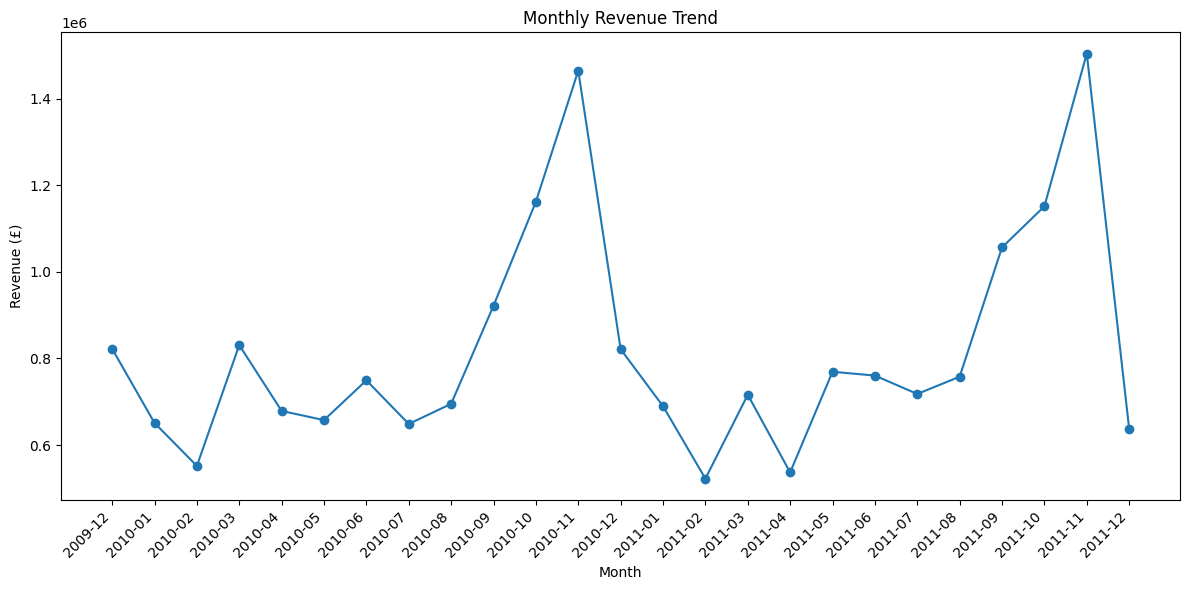

Monthly Revenue Trend saved successfully!


In [ ]:
# ============================================
# VISUALIZATION 1 — MONTHLY REVENUE TREND
# ============================================

monthly_revenue = (
    df_clean
    .groupby('Month')['Revenue']
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['Month'],
    monthly_revenue['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()

# Save permanently to Google Drive
plt.savefig(
    os.path.join(
        visuals_folder,
        'monthly_revenue_trend.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Monthly Revenue Trend saved successfully!")

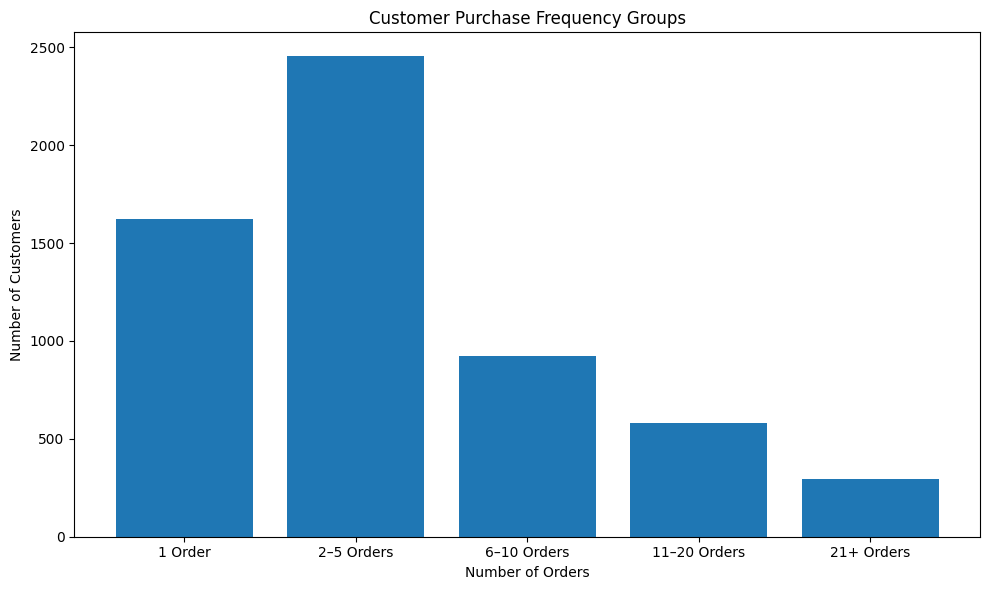

Customer Purchase Frequency chart saved successfully!


In [ ]:
# ============================================
# VISUALIZATION 2 — CUSTOMER PURCHASE FREQUENCY
# ============================================

# Count unique orders for each customer
customer_frequency = (
    customer_df.groupby('Customer ID')['Invoice']
    .nunique()
    .reset_index(name='Frequency')
)

# Create frequency groups
frequency_bins = [0, 1, 5, 10, 20, float('inf')]

frequency_labels = [
    '1 Order',
    '2–5 Orders',
    '6–10 Orders',
    '11–20 Orders',
    '21+ Orders'
]

customer_frequency['Frequency_Group'] = pd.cut(
    customer_frequency['Frequency'],
    bins=frequency_bins,
    labels=frequency_labels
)

frequency_groups = (
    customer_frequency['Frequency_Group']
    .value_counts()
    .reindex(frequency_labels)
)

# Create chart
plt.figure(figsize=(10, 6))

plt.bar(
    frequency_groups.index,
    frequency_groups.values
)

plt.title('Customer Purchase Frequency Groups')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.tight_layout()

# Save permanently
plt.savefig(
    os.path.join(
        visuals_folder,
        'customer_purchase_frequency_groups.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Customer Purchase Frequency chart saved successfully!")

In [ ]:
# ============================================
# RFM CUSTOMER ANALYSIS
# ============================================

# Reference date = last transaction in the dataset
reference_date = df_clean['InvoiceDate'].max()

# Calculate RFM metrics
rfm = (
    customer_df
    .groupby('Customer ID')
    .agg(
        Recency=('InvoiceDate', lambda x:
                 (reference_date - x.max()).days),
        Frequency=('Invoice', 'nunique'),
        Monetary=('Revenue', 'sum')
    )
    .reset_index()
)

# --------------------------------------------
# Create RFM scores (1–5)
# --------------------------------------------

# Recency: lower number of days = better score
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates='drop'
).astype(int)

# Frequency: higher frequency = better score
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending = better score
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print("RFM analysis created successfully!")
print()
print("Customers analysed:", len(rfm))
print("Reference date:", reference_date)
print()
print(rfm.head())

RFM analysis created successfully!

Customers analysed: 5878
Reference date: 2011-12-09 12:50:00

   Customer ID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0      12346.0      325         12  77556.46        2        5        5   
1      12347.0        1          8   4921.53        5        4        5   
2      12348.0       74          5   2019.40        3        4        4   
3      12349.0       18          4   4428.69        5        3        5   
4      12350.0      309          1    334.40        2        1        2   

  RFM_Score  
0       255  
1       545  
2       344  
3       535  
4       212  


In [ ]:
# ============================================
# CUSTOMER SEGMENTATION
# ============================================

def assign_segment(row):

    R = row['R_Score']
    F = row['F_Score']
    M = row['M_Score']

    # Champions
    if R >= 4 and F >= 4 and M >= 4:
        return 'Champions'

    # Loyal Customers
    elif R >= 3 and F >= 4:
        return 'Loyal Customers'

    # At Risk - High Value
    elif R <= 2 and F >= 4 and M >= 4:
        return 'At Risk - High Value'

    # At Risk
    elif R <= 2 and F >= 2:
        return 'At Risk'

    # Potential Loyalists
    elif R >= 4 and F >= 2 and M >= 2:
        return 'Potential Loyalists'

    # New / Promising
    elif R >= 4 and F <= 2:
        return 'New / Promising'

    # Need Attention
    elif R == 3 and F <= 3:
        return 'Need Attention'

    # Low Engagement
    else:
        return 'Low Engagement'


rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# Count customers in each segment
segment_counts = (
    rfm['Segment']
    .value_counts()
)

print("Customer segmentation created!")
print()
print(segment_counts)

Customer segmentation created!

Segment
At Risk                 1308
Champions               1297
Low Engagement           848
Loyal Customers          701
Need Attention           651
Potential Loyalists      613
New / Promising          237
At Risk - High Value     223
Name: count, dtype: int64


In [ ]:
# Show how customers are distributed across RFM score combinations

rfm_combinations = (
    rfm.groupby(['R_Score', 'F_Score', 'M_Score'])
    .size()
    .reset_index(name='Customers')
    .sort_values(
        ['R_Score', 'F_Score', 'M_Score'],
        ascending=False
    )
)

print(rfm_combinations.to_string(index=False))

 R_Score  F_Score  M_Score  Customers
       5        5        5        469
       5        5        4         96
       5        5        3          5
       5        5        2          1
       5        4        5         45
       5        4        4        131
       5        4        3         80
       5        4        2         10
       5        3        5          9
       5        3        4         44
       5        3        3         79
       5        3        2         43
       5        3        1         13
       5        2        5          2
       5        2        4         10
       5        2        3         32
       5        2        2         38
       5        2        1         27
       5        1        5          1
       5        1        3          3
       5        1        2         23
       5        1        1         27
       4        5        5        248
       4        5        4         86
       4        5        3          3
       4    

In [ ]:
# ============================================
# CHECK RFM SCORE PATTERNS
# ============================================

# Count customers by R and F scores
rf_table = pd.crosstab(
    rfm['R_Score'],
    rfm['F_Score']
)

print("Customers by Recency and Frequency Score:")
print(rf_table)

print("\n\nCustomers by Recency Score:")
print(rfm['R_Score'].value_counts().sort_index(ascending=False))

print("\n\nCustomers by Frequency Score:")
print(rfm['F_Score'].value_counts().sort_index(ascending=False))

Customers by Recency and Frequency Score:
F_Score    1    2    3    4    5
R_Score                         
1        513  389  184   72   17
2        303  318  287  210   54
3        192  193  266  319  197
4        114  166  251  308  337
5         54  109  188  266  571


Customers by Recency Score:
R_Score
5    1188
4    1176
3    1167
2    1172
1    1175
Name: count, dtype: int64


Customers by Frequency Score:
F_Score
5    1176
4    1175
3    1176
2    1175
1    1176
Name: count, dtype: int64


In [ ]:
duplicates.head(20)

NameError: name 'duplicates' is not defined

In [ ]:
product_sales[
    product_sales['StockCode'].astype(str) == '23843'
]

NameError: name 'product_sales' is not defined

In [ ]:
print(df_clean['StockCode'].dtype)

print(
    df_clean[df_clean['StockCode'].astype(str) == '23843']
    [['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country', 'Revenue']]
)

In [ ]:
non_product_codes = ['M', 'DOT', 'POST']

df_products = df_clean[
    ~df_clean['StockCode'].isin(non_product_codes)
].copy()

print("Original clean rows:", len(df_clean))
print("Merchandise rows:", len(df_products))
print("Rows excluded:", len(df_clean) - len(df_products))

NameError: name 'df_clean' is not defined

In [ ]:
product_sales = df_products.groupby(
    ['StockCode', 'Description']
).agg(
    Revenue=('Revenue', 'sum'),
    Quantity_Sold=('Quantity', 'sum'),
    Orders=('Invoice', 'nunique')
).reset_index()

product_sales = product_sales.sort_values(
    'Revenue',
    ascending=False
)

product_sales.head(10)

In [ ]:
customer_sales = df_clean[
    df_clean['Customer ID'].notna()
].groupby('Customer ID').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique'),
    Quantity=('Quantity', 'sum')
).reset_index()

customer_sales['AOV'] = (
    customer_sales['Revenue'] / customer_sales['Orders']
)

customer_sales.sort_values(
    'Revenue',
    ascending=False
).head(10)

In [ ]:
customer_sales['Customer_Type'] = customer_sales['Orders'].apply(
    lambda x: 'Repeat' if x >= 2 else 'One-time'
)

customer_type = customer_sales['Customer_Type'].value_counts()

print(customer_type)

In [ ]:
customer_type_percentage = (
    customer_sales['Customer_Type']
    .value_counts(normalize=True) * 100
)

print(customer_type_percentage.round(2))

In [ ]:
customer_type_summary = customer_sales.groupby(
    'Customer_Type'
).agg(
    Customers=('Customer ID', 'count'),
    Revenue=('Revenue', 'sum'),
    Orders=('Orders', 'sum'),
    Avg_Revenue_Per_Customer=('Revenue', 'mean')
).reset_index()

customer_type_summary

NameError: name 'customer_sales' is not defined

In [ ]:
customer_type_summary['Revenue_Share'] = (
    customer_type_summary['Revenue'] / total_revenue * 100
)

customer_type_summary

In [ ]:
one_time_customers = customer_sales[
    customer_sales['Customer_Type'] == 'One-time'
].sort_values(
    'Revenue',
    ascending=False
)

one_time_customers.head(10)

In [ ]:
print("One-time customer revenue: £",
      round(one_time_customers['Revenue'].sum(), 2))

print("Average one-time customer revenue: £",
      round(one_time_customers['Revenue'].mean(), 2))

print("Highest one-time customer revenue: £",
      round(one_time_customers['Revenue'].max(), 2))

NameError: name 'one_time_customers' is not defined

In [ ]:
max_date = df_clean['InvoiceDate'].max()

print("Last transaction date:", max_date)

In [ ]:
customer_recency = df_clean[
    df_clean['Customer ID'].notna()
].groupby('Customer ID').agg(
    Last_Purchase=('InvoiceDate', 'max')
).reset_index()

customer_recency['Recency_Days'] = (
    max_date - customer_recency['Last_Purchase']
).dt.days

customer_recency.head(10)

In [ ]:
rfm = customer_sales[
    ['Customer ID', 'Orders', 'Revenue']
].merge(
    customer_recency[
        ['Customer ID', 'Recency_Days']
    ],
    on='Customer ID'
)

rfm = rfm.rename(columns={
    'Orders': 'Frequency',
    'Revenue': 'Monetary'
})

rfm.head(10)

NameError: name 'customer_sales' is not defined

In [ ]:
rfm[['Recency_Days', 'Frequency', 'Monetary']].describe()

In [ ]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency_Days'],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(int).astype(str) +
    rfm['F_Score'].astype(int).astype(str) +
    rfm['M_Score'].astype(int).astype(str)
)

rfm.head(10)

In [ ]:
def segment_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'

    elif r >= 3 and f >= 4:
        return 'Loyal Customers'

    elif r >= 4 and m >= 4:
        return 'Potential Loyalists'

    elif r <= 2 and f >= 4 and m >= 4:
        return 'At Risk - High Value'

    elif r <= 2 and f >= 3:
        return 'At Risk'

    elif r >= 4 and f <= 2:
        return 'New / Promising'

    elif r <= 2 and f <= 2:
        return 'Low Engagement'

    else:
        return 'Need Attention'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

rfm['Segment'].value_counts()

NameError: name 'rfm' is not defined

In [ ]:
def segment_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'

    elif r >= 3 and f >= 4:
        return 'Loyal Customers'

    elif r >= 4 and m >= 4:
        return 'Potential Loyalists'

    elif r <= 2 and f >= 4 and m >= 4:
        return 'At Risk - High Value'

    elif r <= 2 and f >= 3:
        return 'At Risk'

    elif r >= 4 and f <= 2:
        return 'New / Promising'

    elif r <= 2 and f <= 2:
        return 'Low Engagement'

    else:
        return 'Need Attention'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

rfm['Segment'].value_counts()

,count
Segment,
Low Engagement,1523
Champions,1297
Need Attention,974
Loyal Customers,701
At Risk,601
New / Promising,417
At Risk - High Value,223
Potential Loyalists,142


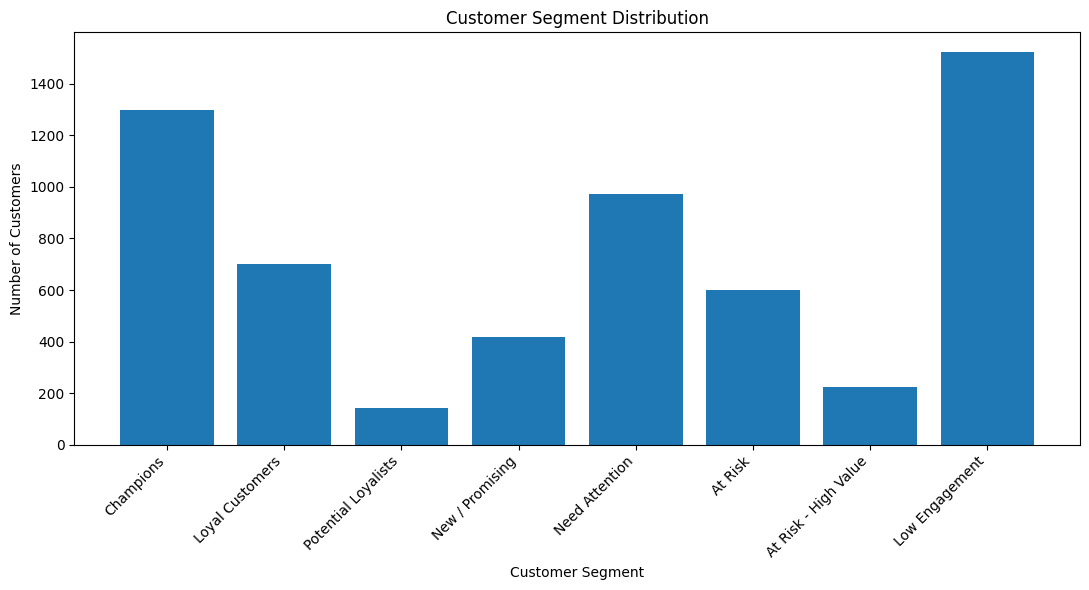

Customer Segment Distribution saved successfully!


In [ ]:
# ============================================
# VISUALIZATION 3 — CUSTOMER SEGMENT DISTRIBUTION
# ============================================

segment_order = [
    'Champions',
    'Loyal Customers',
    'Potential Loyalists',
    'New / Promising',
    'Need Attention',
    'At Risk',
    'At Risk - High Value',
    'Low Engagement'
]

segment_counts = (
    rfm['Segment']
    .value_counts()
    .reindex(segment_order)
)

plt.figure(figsize=(11, 6))

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title('Customer Segment Distribution')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()

# Save permanently to Google Drive
plt.savefig(
    os.path.join(
        visuals_folder,
        'customer_segment_distribution.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Customer Segment Distribution saved successfully!")

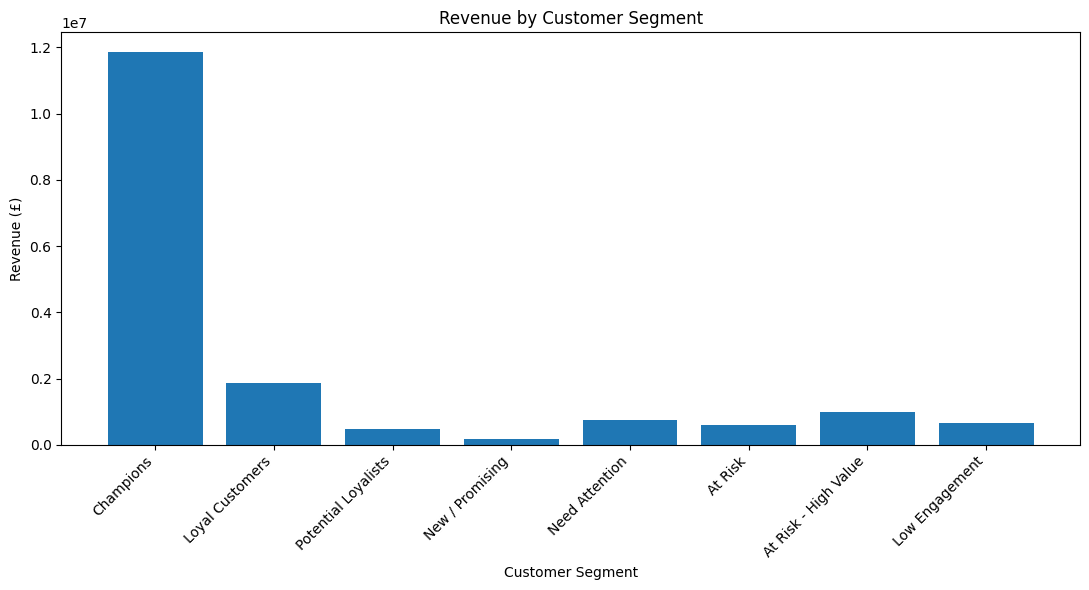

Revenue by Customer Segment saved successfully!


In [ ]:
# ============================================
# VISUALIZATION 4 — REVENUE BY CUSTOMER SEGMENT
# ============================================

segment_revenue = (
    rfm.groupby('Segment')['Monetary']
    .sum()
    .reindex(segment_order)
)

plt.figure(figsize=(11, 6))

plt.bar(
    segment_revenue.index,
    segment_revenue.values
)

plt.title('Revenue by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Revenue (£)')

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()

# Save permanently to Google Drive
plt.savefig(
    os.path.join(
        visuals_folder,
        'revenue_by_customer_segment.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Revenue by Customer Segment saved successfully!")

In [ ]:
# ============================================
# COUNTRY ANALYSIS
# ============================================

country_analysis = (
    df_clean
    .groupby('Country')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique'),
        Customers=('Customer ID', 'nunique')
    )
    .reset_index()
)

country_analysis['AOV'] = (
    country_analysis['Revenue'] /
    country_analysis['Orders']
)

country_analysis['Revenue_Share'] = (
    country_analysis['Revenue'] /
    total_revenue * 100
)

# Sort by revenue
country_analysis = country_analysis.sort_values(
    'Revenue',
    ascending=False
)

print("Country analysis created successfully!")
print()

print(
    country_analysis
    .head(10)
    .to_string(index=False)
)

Country analysis created successfully!

       Country      Revenue  Orders  Customers         AOV  Revenue_Share
United Kingdom 17410569.687   36536       5350  476.531905      85.026522
          EIRE   658767.310     626          5 1052.343946       3.217166
   Netherlands   554038.090     228         22 2429.991623       2.705709
       Germany   425019.711     789        107  538.681510       2.075633
        France   350456.090     622         95  563.434228       1.711493
     Australia   169283.460      95         15 1781.931158       0.826715
         Spain   108332.490     154         41  703.457727       0.529054
   Switzerland   100685.590      93         22 1082.640753       0.491710
        Sweden    91869.820     105         19  874.950667       0.448657
       Denmark    68580.690      43         12 1594.899767       0.334922


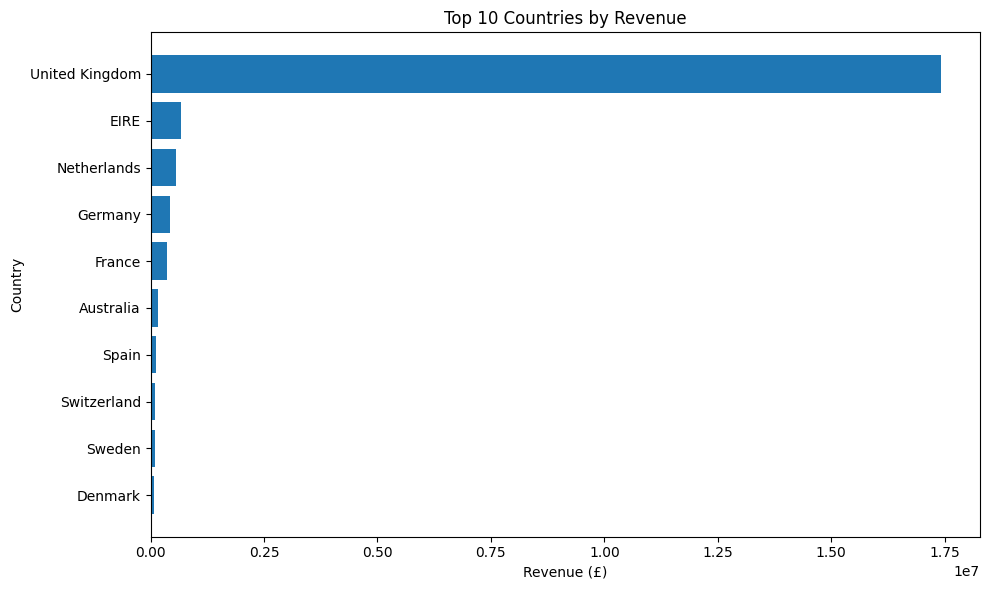

Top 10 Countries by Revenue saved successfully!


In [ ]:
# ============================================
# VISUALIZATION 5 — TOP 10 COUNTRIES BY REVENUE
# ============================================

top_countries = country_analysis.head(10).sort_values(
    'Revenue',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries['Country'],
    top_countries['Revenue']
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')

plt.tight_layout()

# Save permanently to Google Drive
plt.savefig(
    os.path.join(
        visuals_folder,
        'top_10_countries_by_revenue.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Top 10 Countries by Revenue saved successfully!")

In [ ]:
# ============================================
# PRODUCT ANALYSIS — PREPARE DATA
# ============================================

# Codes that are not actual products
non_product_codes = [
    'M',
    'DOT',
    'POST',
    'B',
    'AMAZONFEE',
    'ADJUST',
    'ADJUST2'
]

product_analysis = df_clean[
    ~df_clean['StockCode'].isin(non_product_codes)
].copy()

print("Product analysis dataset created!")
print("Rows:", len(product_analysis))
print("Rows excluded:", len(df_clean) - len(product_analysis))

Product analysis dataset created!
Rows: 1003758
Rows excluded: 4156


In [ ]:
segment_summary = rfm.groupby('Segment').agg(
    Customers=('Customer ID', 'count'),
    Revenue=('Monetary', 'sum'),
    Avg_Revenue=('Monetary', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Recency=('Recency_Days', 'mean')
).reset_index()

segment_summary.sort_values(
    'Revenue',
    ascending=False
)

In [ ]:
segment_summary['Revenue_Share'] = (
    segment_summary['Revenue'] / total_revenue * 100
)

segment_summary = segment_summary.sort_values(
    'Revenue',
    ascending=False
)

segment_summary

In [ ]:
print(
    "Champions revenue share:",
    round(
        segment_summary.loc[
            segment_summary['Segment'] == 'Champions',
            'Revenue_Share'
        ].iloc[0],
        2
    ),
    "%"
)

print(
    "At Risk - High Value revenue:",
    round(
        segment_summary.loc[
            segment_summary['Segment'] == 'At Risk - High Value',
            'Revenue'
        ].iloc[0],
        2
    )
)

In [ ]:
import matplotlib.pyplot as plt

monthly_revenue = df_clean.groupby(
    df_clean['InvoiceDate'].dt.to_period('M')
)['Revenue'].sum()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_trend.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
segment_counts = rfm['Segment'].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.savefig(
    'customer_segment_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
segment_revenue = segment_summary.sort_values(
    'Revenue',
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    segment_revenue['Segment'],
    segment_revenue['Revenue']
)

plt.title('Revenue by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.savefig(
    'revenue_by_customer_segment.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
top_products = product_sales.head(10).sort_values(
    'Revenue',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_products['Description'],
    top_products['Revenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')

plt.tight_layout()

plt.savefig(
    'top_10_products_by_revenue.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

NameError: name 'product_sales' is not defined

In [ ]:
top_products_by_orders = product_sales.sort_values(
    'Orders',
    ascending=False
).head(10)

top_products_by_orders

In [ ]:
top_products_by_quantity = product_sales.sort_values(
    'Quantity_Sold',
    ascending=False
).head(10)

top_products_by_quantity

In [ ]:
product_sales['Revenue_per_Unit'] = (
    product_sales['Revenue'] /
    product_sales['Quantity_Sold']
)

top_products_by_unit_value = product_sales.sort_values(
    'Revenue_per_Unit',
    ascending=False
).head(10)

top_products_by_unit_value

In [ ]:
product_analysis = product_sales[
    (product_sales['Quantity_Sold'] > 0) &
    (product_sales['Revenue'] > 0) &
    (~product_sales['Description'].str.contains(
        'adjust|amazon|fee|bad debt',
        case=False,
        na=False
    ))
].copy()

product_analysis['Revenue_per_Unit'] = (
    product_analysis['Revenue'] /
    product_analysis['Quantity_Sold']
)

top_products_by_unit_value = product_analysis.sort_values(
    'Revenue_per_Unit',
    ascending=False
).head(10)

top_products_by_unit_value

In [ ]:
# ============================================
# RECREATE PRODUCT SALES DATA
# ============================================

product_sales = (
    df_clean
    .groupby(['StockCode', 'Description'])
    .agg(
        Quantity_Sold=('Quantity', 'sum'),
        Revenue=('Revenue', 'sum'),
        Orders=('Invoice', 'nunique')
    )
    .reset_index()
)

print("product_sales created successfully!")
print("Rows:", len(product_sales))
print(product_sales.head())

product_sales created successfully!
Rows: 5630
  StockCode                  Description  Quantity_Sold  Revenue  Orders
0     10002  INFLATABLE POLITICAL GLOBE            8671  6942.26     362
1     10080     GROOVY CACTUS INFLATABLE            315   129.29      27
2     10109         BENDY COLOUR PENCILS              4     1.68       1
3     10120                 DOGGY RUBBER            664   142.74      73
4     10125      MINI FUNKY DESIGN TAPES           2103  1715.78     167


In [ ]:
# ============================================
# PRODUCT ANALYSIS
# ============================================

product_analysis = product_sales[
    (product_sales['Quantity_Sold'] > 0) &
    (product_sales['Revenue'] > 0) &
    (~product_sales['Description'].str.contains(
        'adjust|amazon|fee|bad debt',
        case=False,
        na=False
    ))
].copy()

product_analysis['Revenue_per_Unit'] = (
    product_analysis['Revenue'] /
    product_analysis['Quantity_Sold']
)

print("Product analysis recreated successfully!")
print("Products analysed:", len(product_analysis))

Product analysis recreated successfully!
Products analysed: 5585


In [ ]:
# ============================================
# TOP 10 PRODUCTS BY REVENUE
# ============================================

top_products_by_revenue = (
    product_analysis
    .sort_values('Revenue', ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
print(
    top_products_by_revenue[
        ['Description', 'Revenue', 'Quantity_Sold', 'Orders']
    ].to_string(index=False)
)

Top 10 Products by Revenue:
                       Description   Revenue  Quantity_Sold  Orders
                            Manual 339599.81           9630     785
          REGENCY CAKESTAND 3 TIER 330590.32          26478    3918
                    DOTCOM POSTAGE 309854.11           1415    1415
WHITE HANGING HEART T-LIGHT HOLDER 257546.20          94142    5356
       PAPER CRAFT , LITTLE BIRDIE 168469.60          80995       1
                     PARTY BUNTING 148318.28          28200    2674
           JUMBO BAG RED RETROSPOT 145961.83          77280    3245
     ASSORTED COLOUR BIRD ORNAMENT 129324.49          80082    2807
                           POSTAGE 125682.42           5363    1851
   PAPER CHAIN KIT 50'S CHRISTMAS  117760.29          35084    2018


In [ ]:
# Exclude non-merchandise / administrative entries
excluded_products = [
    'Manual',
    'DOTCOM POSTAGE',
    'POSTAGE'
]

merchandise_products = product_analysis[
    ~product_analysis['Description'].isin(excluded_products)
].copy()

top_10_merchandise_revenue = (
    merchandise_products
    .sort_values('Revenue', ascending=False)
    .head(10)
)

print("Top 10 Actual Products by Revenue:")
print(
    top_10_merchandise_revenue[
        ['Description', 'Revenue', 'Quantity_Sold', 'Orders']
    ].to_string(index=False)
)

Top 10 Actual Products by Revenue:
                        Description   Revenue  Quantity_Sold  Orders
           REGENCY CAKESTAND 3 TIER 330590.32          26478    3918
 WHITE HANGING HEART T-LIGHT HOLDER 257546.20          94142    5356
        PAPER CRAFT , LITTLE BIRDIE 168469.60          80995       1
                      PARTY BUNTING 148318.28          28200    2674
            JUMBO BAG RED RETROSPOT 145961.83          77280    3245
      ASSORTED COLOUR BIRD ORNAMENT 129324.49          80082    2807
    PAPER CHAIN KIT 50'S CHRISTMAS  117760.29          35084    2018
     MEDIUM CERAMIC TOP STORAGE JAR  81700.92          78033     247
                      CHILLI LIGHTS  80540.88          15841    1135
ROTATING SILVER ANGELS T-LIGHT HLDR  71300.40          31409     756


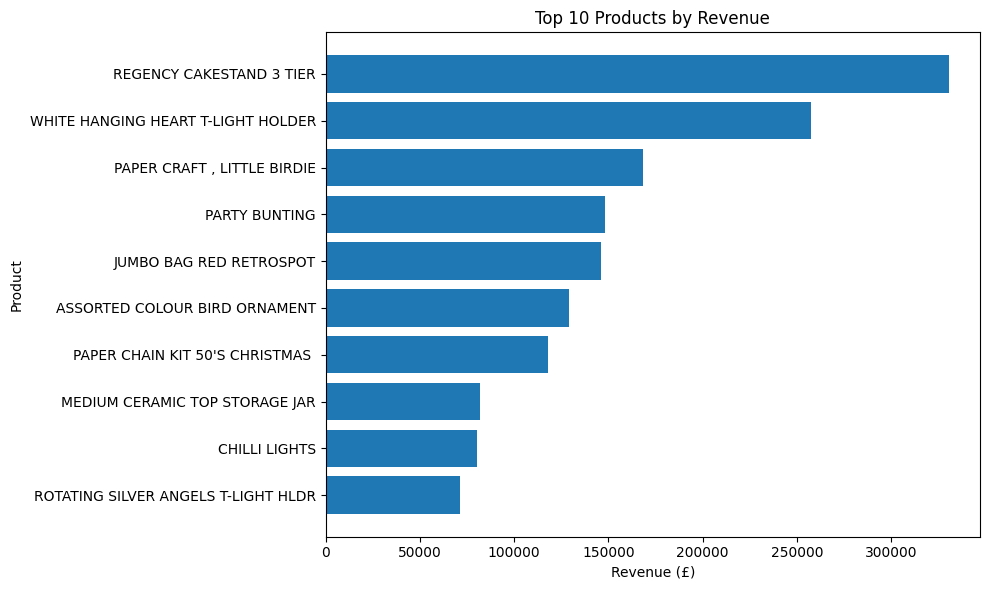

Chart saved to: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations/top_10_products_by_revenue.png


In [ ]:
import matplotlib.pyplot as plt
import os

# Prepare data for chart
chart_data = top_10_merchandise_revenue.sort_values(
    'Revenue',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data['Description'],
    chart_data['Revenue']
)

plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.title('Top 10 Products by Revenue')

plt.tight_layout()

# Save permanently to Google Drive
chart_path = os.path.join(
    visuals_folder,
    'top_10_products_by_revenue.png'
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Chart saved to:", chart_path)

In [ ]:
top_10_products_by_quantity = (
    merchandise_products
    .sort_values('Quantity_Sold', ascending=False)
    .head(10)
)

print("Top 10 Actual Products by Quantity Sold:")
print(
    top_10_products_by_quantity[
        ['Description', 'Quantity_Sold', 'Revenue', 'Orders']
    ].to_string(index=False)
)

Top 10 Actual Products by Quantity Sold:
                       Description  Quantity_Sold   Revenue  Orders
 WORLD WAR 2 GLIDERS ASSTD DESIGNS         106139  24445.61    1019
WHITE HANGING HEART T-LIGHT HOLDER          94142 257546.20    5356
       PAPER CRAFT , LITTLE BIRDIE          80995 168469.60       1
     ASSORTED COLOUR BIRD ORNAMENT          80082 129324.49    2807
    MEDIUM CERAMIC TOP STORAGE JAR          78033  81700.92     247
           JUMBO BAG RED RETROSPOT          77280 145961.83    3245
               BROCADE RING PURSE           70369  14766.42     456
PACK OF 60 PINK PAISLEY CAKE CASES          56061  28081.73    1993
       60 TEATIME FAIRY CAKE CASES          54028  27041.21    2127
              SMALL POPCORN HOLDER          48561  42699.89    1407


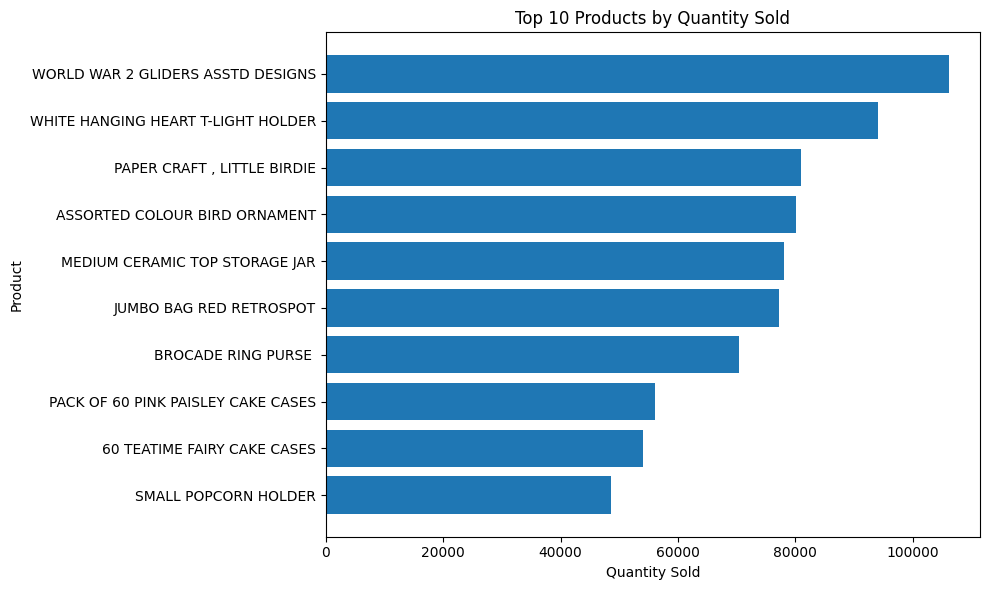

Chart saved to: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations/top_10_products_by_quantity.png


In [ ]:
import matplotlib.pyplot as plt
import os

# Prepare data for chart
chart_data = top_10_products_by_quantity.sort_values(
    'Quantity_Sold',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data['Description'],
    chart_data['Quantity_Sold']
)

plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.title('Top 10 Products by Quantity Sold')

plt.tight_layout()

# Save permanently to Google Drive
chart_path = os.path.join(
    visuals_folder,
    'top_10_products_by_quantity.png'
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Chart saved to:", chart_path)

In [ ]:
top_volume_analysis = top_10_products_by_quantity.copy()

top_volume_analysis['Revenue_per_Unit'] = (
    top_volume_analysis['Revenue'] /
    top_volume_analysis['Quantity_Sold']
)

print("Top Volume Products - Revenue per Unit:")
print(
    top_volume_analysis[
        ['Description', 'Quantity_Sold', 'Revenue', 'Orders', 'Revenue_per_Unit']
    ].to_string(index=False)
)

Top Volume Products - Revenue per Unit:
                       Description  Quantity_Sold   Revenue  Orders  Revenue_per_Unit
 WORLD WAR 2 GLIDERS ASSTD DESIGNS         106139  24445.61    1019          0.230317
WHITE HANGING HEART T-LIGHT HOLDER          94142 257546.20    5356          2.735721
       PAPER CRAFT , LITTLE BIRDIE          80995 168469.60       1          2.080000
     ASSORTED COLOUR BIRD ORNAMENT          80082 129324.49    2807          1.614901
    MEDIUM CERAMIC TOP STORAGE JAR          78033  81700.92     247          1.047005
           JUMBO BAG RED RETROSPOT          77280 145961.83    3245          1.888740
               BROCADE RING PURSE           70369  14766.42     456          0.209843
PACK OF 60 PINK PAISLEY CAKE CASES          56061  28081.73    1993          0.500914
       60 TEATIME FAIRY CAKE CASES          54028  27041.21    2127          0.500504
              SMALL POPCORN HOLDER          48561  42699.89    1407          0.879304


In [ ]:
# Classify customers based on number of orders
customer_type = customer_frequency.copy()

customer_type['Customer_Type'] = np.where(
    customer_type['Frequency'] == 1,
    'One-Time Customer',
    'Repeat Customer'
)

customer_type_summary = (
    customer_type['Customer_Type']
    .value_counts()
    .reset_index()
)

customer_type_summary.columns = ['Customer_Type', 'Customers']

customer_type_summary['Percentage'] = (
    customer_type_summary['Customers'] /
    customer_type_summary['Customers'].sum()
) * 100

print("Customer Retention Summary:")
print(customer_type_summary.to_string(index=False))

Customer Retention Summary:
    Customer_Type  Customers  Percentage
  Repeat Customer       4255   72.388568
One-Time Customer       1623   27.611432


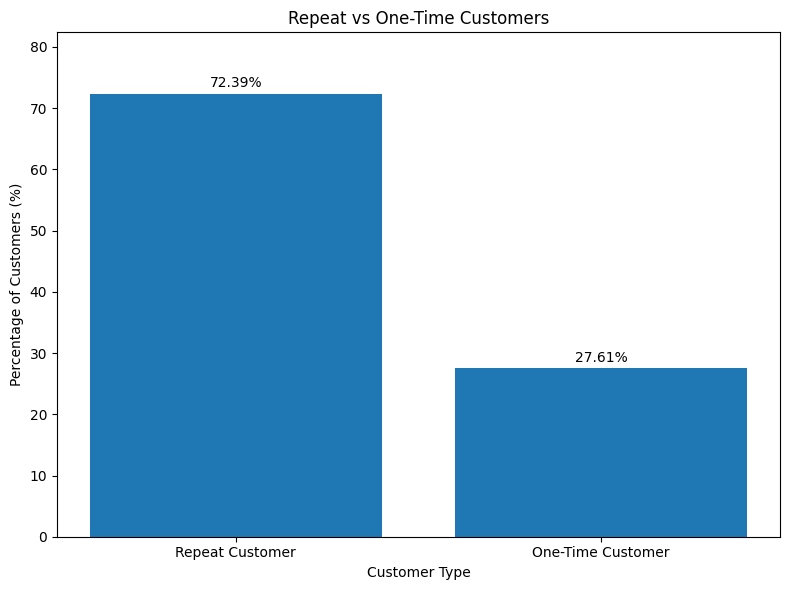

Chart saved to: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations/repeat_vs_one_time_customers.png


In [ ]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8, 6))

plt.bar(
    customer_type_summary['Customer_Type'],
    customer_type_summary['Percentage']
)

plt.xlabel('Customer Type')
plt.ylabel('Percentage of Customers (%)')
plt.title('Repeat vs One-Time Customers')

# Add percentage labels
for i, value in enumerate(customer_type_summary['Percentage']):
    plt.text(
        i,
        value + 1,
        f'{value:.2f}%',
        ha='center'
    )

plt.ylim(0, max(customer_type_summary['Percentage']) + 10)
plt.tight_layout()

# Save permanently to Google Drive
chart_path = os.path.join(
    visuals_folder,
    'repeat_vs_one_time_customers.png'
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Chart saved to:", chart_path)

In [ ]:
# Add customer type to the customer-level RFM data
customer_revenue = rfm[['Customer ID', 'Monetary']].copy()

customer_revenue = customer_revenue.merge(
    customer_type[['Customer ID', 'Customer_Type']],
    on='Customer ID',
    how='left'
)

# Calculate revenue by customer type
retention_revenue = (
    customer_revenue
    .groupby('Customer_Type')
    .agg(
        Customers=('Customer ID', 'count'),
        Revenue=('Monetary', 'sum')
    )
    .reset_index()
)

retention_revenue['Revenue_Share'] = (
    retention_revenue['Revenue'] /
    retention_revenue['Revenue'].sum()
) * 100

print("Revenue by Customer Type:")
print(
    retention_revenue.to_string(index=False)
)

Revenue by Customer Type:
    Customer_Type  Customers      Revenue  Revenue_Share
One-Time Customer       1623   560272.562       3.224627
  Repeat Customer       4255 16814531.706      96.775373


In [ ]:
retention_revenue['Average_Revenue_Per_Customer'] = (
    retention_revenue['Revenue'] /
    retention_revenue['Customers']
)

print("Average Revenue per Customer:")
print(
    retention_revenue[
        ['Customer_Type', 'Customers', 'Average_Revenue_Per_Customer']
    ].to_string(index=False)
)

Average Revenue per Customer:
    Customer_Type  Customers  Average_Revenue_Per_Customer
One-Time Customer       1623                    345.207986
  Repeat Customer       4255                   3951.711329


In [ ]:
frequency_summary = (
    customer_frequency
    .assign(
        Frequency_Group=pd.cut(
            customer_frequency['Frequency'],
            bins=[0, 1, 5, 10, 20, float('inf')],
            labels=['1 Order', '2–5 Orders', '6–10 Orders', '11–20 Orders', '21+ Orders']
        )
    )
    .groupby('Frequency_Group', observed=False)
    .agg(
        Customers=('Customer ID', 'count')
    )
    .reset_index()
)

frequency_summary['Percentage'] = (
    frequency_summary['Customers'] /
    frequency_summary['Customers'].sum()
) * 100

print("Customer Purchase Frequency:")
print(frequency_summary.to_string(index=False))

Customer Purchase Frequency:
Frequency_Group  Customers  Percentage
        1 Order       1623   27.611432
     2–5 Orders       2454   41.748894
    6–10 Orders        925   15.736645
   11–20 Orders        579    9.850289
     21+ Orders        297    5.052739


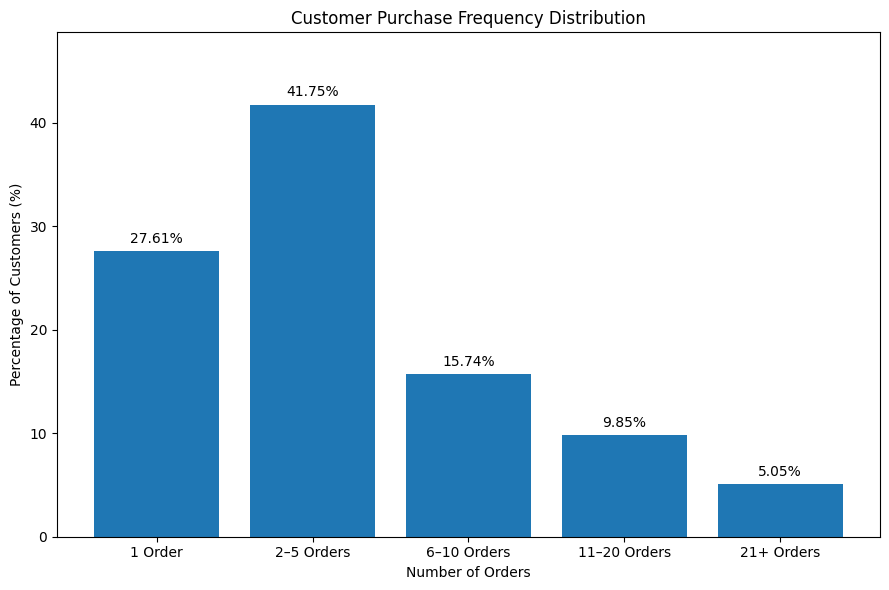

Chart saved to: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations/customer_purchase_frequency_distribution.png


In [ ]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(9, 6))

plt.bar(
    frequency_summary['Frequency_Group'].astype(str),
    frequency_summary['Percentage']
)

plt.xlabel('Number of Orders')
plt.ylabel('Percentage of Customers (%)')
plt.title('Customer Purchase Frequency Distribution')

# Add percentage labels
for i, value in enumerate(frequency_summary['Percentage']):
    plt.text(
        i,
        value + 0.8,
        f'{value:.2f}%',
        ha='center'
    )

plt.ylim(0, max(frequency_summary['Percentage']) + 7)
plt.tight_layout()

chart_path = os.path.join(
    visuals_folder,
    'customer_purchase_frequency_distribution.png'
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Chart saved to:", chart_path)

In [ ]:
segment_summary = (
    rfm
    .groupby('Segment')
    .agg(
        Customers=('Customer ID', 'count'),
        Revenue=('Monetary', 'sum'),
        Avg_Revenue_Per_Customer=('Monetary', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Recency=('Recency', 'mean')
    )
    .reset_index()
)

segment_summary['Revenue_Share'] = (
    segment_summary['Revenue'] /
    segment_summary['Revenue'].sum()
) * 100

segment_summary = segment_summary.sort_values(
    'Revenue',
    ascending=False
)

print("Customer Segment Analysis:")
print(segment_summary.to_string(index=False))

Customer Segment Analysis:
             Segment  Customers      Revenue  Avg_Revenue_Per_Customer  Avg_Frequency  Avg_Recency  Revenue_Share
           Champions       1297 11859591.495               9143.863913      17.105628    18.961449      68.257411
     Loyal Customers        701  1856667.025               2648.597753       7.736091    83.368046      10.685974
At Risk - High Value        223   982122.182               4404.135345       8.977578   341.295964       5.652565
      Need Attention        974   756054.644                776.236801       2.396304    80.588296       4.351443
      Low Engagement       1523   654426.702                429.695799       1.252791   458.281024       3.766527
             At Risk        601   607262.130               1010.419517       3.442596   378.046589       3.495073
 Potential Loyalists        142   482666.450               3399.059507       3.154930    23.084507       2.777968
     New / Promising        417   176013.640                4

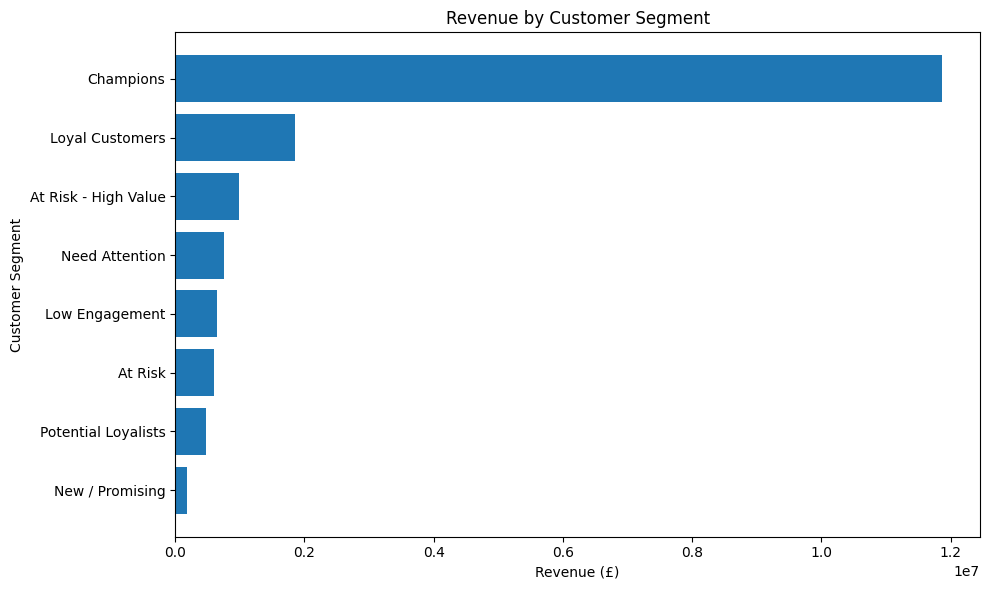

Chart saved to: /content/drive/MyDrive/Ecommerce_Analysis_Project/Visualizations/revenue_by_customer_segment_detailed.png


In [ ]:
import matplotlib.pyplot as plt
import os

chart_data = segment_summary.sort_values(
    'Revenue',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data['Segment'],
    chart_data['Revenue']
)

plt.xlabel('Revenue (£)')
plt.ylabel('Customer Segment')
plt.title('Revenue by Customer Segment')

plt.tight_layout()

chart_path = os.path.join(
    visuals_folder,
    'revenue_by_customer_segment_detailed.png'
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Chart saved to:", chart_path)

In [ ]:
at_risk_high_value = segment_summary[
    segment_summary['Segment'] == 'At Risk - High Value'
].copy()

print("At Risk - High Value Customer Analysis:")
print(
    at_risk_high_value[
        [
            'Segment',
            'Customers',
            'Revenue',
            'Avg_Revenue_Per_Customer',
            'Avg_Frequency',
            'Avg_Recency',
            'Revenue_Share'
        ]
    ].to_string(index=False)
)

print("\nPotential Revenue Opportunity:")
print(
    f"Revenue currently associated with this segment: "
    f"£{at_risk_high_value['Revenue'].iloc[0]:,.2f}"
)

At Risk - High Value Customer Analysis:
             Segment  Customers    Revenue  Avg_Revenue_Per_Customer  Avg_Frequency  Avg_Recency  Revenue_Share
At Risk - High Value        223 982122.182               4404.135345       8.977578   341.295964       5.652565

Potential Revenue Opportunity:
Revenue currently associated with this segment: £982,122.18


In [ ]:
frequency_distribution = rfm['Frequency'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

plt.bar(
    frequency_distribution.index,
    frequency_distribution.values
)

plt.title('Customer Purchase Frequency')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.savefig(
    'customer_purchase_frequency.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
duplicates['Invoice'].value_counts().head(10)

In [ ]:
df_clean = df_sales.drop_duplicates().copy()

print("Before removing duplicates:", len(df_sales))
print("After removing duplicates:", len(df_clean))
print("Duplicates removed:", len(df_sales) - len(df_clean))

In [ ]:
print("Remaining duplicate rows:", df_clean.duplicated().sum())

In [ ]:
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

df_clean[['Quantity', 'Price', 'Revenue']].head()

NameError: name 'df_clean' is not defined

In [ ]:
print("Total Revenue: £", round(df_clean['Revenue'].sum(), 2))

In [ ]:
total_revenue = df_clean['Revenue'].sum()

total_orders = df_clean['Invoice'].nunique()

total_customers = df_clean['Customer ID'].nunique()

average_order_value = total_revenue / total_orders

print("Total Revenue: £", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value: £", round(average_order_value, 2))

In [ ]:
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')

monthly_sales = df_clean.groupby('Month')['Revenue'].sum().reset_index()

monthly_sales

In [ ]:
best_month = monthly_sales.loc[monthly_sales['Revenue'].idxmax()]
worst_month = monthly_sales.loc[monthly_sales['Revenue'].idxmin()]

print("Best month:")
print(best_month)

print("\nWorst month:")
print(worst_month)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales['Month'].astype(str),
    monthly_sales['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
monthly_kpis = df_clean.groupby('Month').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique')
).reset_index()

monthly_kpis['AOV'] = monthly_kpis['Revenue'] / monthly_kpis['Orders']

monthly_kpis

In [ ]:
monthly_kpis.sort_values('Revenue', ascending=False).head(5)

In [ ]:
country_sales = df_clean.groupby('Country').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique'),
    Customers=('Customer ID', 'nunique')
).reset_index()

country_sales['AOV'] = country_sales['Revenue'] / country_sales['Orders']

country_sales.sort_values('Revenue', ascending=False).head(10)

In [ ]:
country_sales.sort_values('Revenue', ascending=False).head(10)

In [ ]:
country_sales['Revenue_Share'] = (
    country_sales['Revenue'] / total_revenue * 100
)

country_sales.sort_values(
    'Revenue',
    ascending=False
).head(10)

In [ ]:
uk_share = country_sales.loc[
    country_sales['Country'] == 'United Kingdom',
    'Revenue_Share'
].iloc[0]

print("UK revenue share:", round(uk_share, 2), "%")

NameError: name 'country_sales' is not defined

In [ ]:
product_sales = df_clean.groupby(
    ['StockCode', 'Description']
).agg(
    Revenue=('Revenue', 'sum'),
    Quantity_Sold=('Quantity', 'sum'),
    Orders=('Invoice', 'nunique')
).reset_index()

product_sales = product_sales.sort_values(
    'Revenue',
    ascending=False
)

product_sales.head(10)

NameError: name 'df_clean' is not defined

In [ ]:
special_codes = ['M', 'DOT', 'POST']

df_clean[df_clean['StockCode'].isin(special_codes)][
    ['StockCode', 'Description', 'Quantity', 'Price', 'Revenue']
].groupby(
    ['StockCode', 'Description']
).agg(
    Revenue=('Revenue', 'sum'),
    Quantity=('Quantity', 'sum'),
    Transactions=('StockCode', 'size')
).reset_index()

In [ ]:
df_clean[
    df_clean['StockCode'] == '23843'
][[
    'Invoice',
    'StockCode',
    'Description',
    'Quantity',
    'Price',
    'Customer ID',
    'Country',
    'Revenue'
]]

In [ ]:
df_clean[
    df_clean['StockCode'] == '23843'
][[
    'Invoice',
    'StockCode',
    'Description',
    'Quantity',
    'Price',
    'Customer ID',
    'Country',
    'Revenue'
]]

In [ ]:
df_clean[df_clean['StockCode'] == '23843'].shape

In [ ]:
df_clean[df_clean['StockCode'] == '23843'].to_string(index=False)

NameError: name 'df_clean' is not defined

In [ ]:
import zipfile

zip_path = "/content/online+retail+ii.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())

In [ ]:
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/ecommerce_data')

print("File extracted successfully!")

In [ ]:
file_path = "/content/ecommerce_data/online_retail_II.xlsx"

excel_file = pd.ExcelFile(file_path)

print(excel_file.sheet_names)

In [ ]:
df_2009_2010 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df_2010_2011 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

print("2009-2010:", df_2009_2010.shape)
print("2010-2011:", df_2010_2011.shape)

In [ ]:
df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)

print("Total rows:", len(df))
print("Total columns:", len(df.columns))

In [ ]:
print(df.columns)

In [ ]:
df.head()

In [ ]:
df.info()

In [ ]:
missing = df.isnull().sum()

print(missing)

In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.round(2))

In [ ]:
df[df['Customer ID'].isnull()].head(10)

In [ ]:
df[df['Customer ID'].isnull()]['Country'].value_counts().head(10)

In [ ]:
negative_qty = df[df['Quantity'] < 0]

print("Negative quantity rows:", len(negative_qty))
print("Percentage:", round(len(negative_qty) / len(df) * 100, 2), "%")

In [ ]:
negative_qty.head(10)

In [ ]:
print("Invoices starting with C:",
      df['Invoice'].astype(str).str.startswith('C').sum())

print("Negative quantity rows:",
      (df['Quantity'] < 0).sum())

In [ ]:
df[df['Invoice'].astype(str).str.startswith('C')][['Invoice', 'Quantity']].head(10)

In [ ]:
negative_non_c = df[
    (df['Quantity'] < 0) &
    (~df['Invoice'].astype(str).str.startswith('C'))
]

print("Negative quantity without C:", len(negative_non_c))

In [ ]:
negative_non_c.head(20)

In [ ]:
print("Zero-price rows:", (df['Price'] == 0).sum())
print("Negative-price rows:", (df['Price'] < 0).sum())

In [ ]:
print("Zero-price percentage:",
      round((df['Price'] == 0).mean() * 100, 2), "%")

In [ ]:
df_sales = df[
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].copy()

print("Original rows:", len(df))
print("Valid sales rows:", len(df_sales))
print("Rows removed:", len(df) - len(df_sales))

In [ ]:
print("Percentage of data retained:",
      round(len(df_sales) / len(df) * 100, 2), "%")

In [ ]:
print("Negative/zero quantities:",
      (df_sales['Quantity'] <= 0).sum())

print("Zero/negative prices:",
      (df_sales['Price'] <= 0).sum())

In [ ]:
print("Duplicate rows:", df_sales.duplicated().sum())